# Notebook Dedicated to Demonstrate the Correlation between Directionality and PMT Charges

In [1]:
import numpy as np
import glob
import matplotlib.pyplot as plt
import seaborn as sn

# Functions

In [2]:
def calculate_integrated_charge_per_event(npz_file, t_min=-3.0, t_max=1.0, save_output=None):
    """
    Compute the total charge acumulated by each PMT hit type per event, i.e.,
    the charge of all PMTs is the summed for each hit_type.
    
    Compute the charge acumulated by each hit PMT id of each hit_type per event.
    The hit types of interest are hit_type = 2 (pure scintillator) and hit_type = 3 
    (Cherenkov plus scintillation light).
    
    The PMTs are selected only through a time residual cut.

    Parameters*:
    -npz_file: Directory where are the files to be analyzed in npz format.
    .t_min, t_max: min and max time residual window limits to select hit PMTs
    -save_output: defaul to None. Directory where to save the analysis results.

    Returns: results (npz array with the analysis results)
    """
    print(f"Loading Files: {npz_file}")
    data = np.load(npz_file)

    # Extract the data
    mcid = data['mcid']
    evtid = data['evtid']
    hit_pmt_id = data['hit_pmt_id']
    t_res = data['time_residual_recons'] 
    qhs = data['hit_qhs']
    hit_type = data['hit_type']

    # 1. Perform the tres cut
    time_mask = (t_res >= t_min) & (t_res <= t_max)

    mcid_cut = mcid[time_mask]
    evtid_cut = evtid[time_mask]
    hit_pmt_id_cut = hit_pmt_id[time_mask]
    qhs_cut = qhs[time_mask]
    hit_type_cut = hit_type[time_mask]

    # Identify the events: Use mcid and evtid to avoid mixing the events
    unique_events, event_indices = np.unique(
        np.column_stack((mcid, evtid)), axis=0, return_index=True
    )

    # Structure of the output/results
    results = {
        'mcid': [],
        'evtid': [],
        'q_tot_scint_only': [],   # Carga integrada de todos los hit_type == 2 por evento
        'q_tot_cher_scint': [],   # Carga integrada de todos los hit_type == 3 por evento
        'q_per_pmt_scint_only': [],       # Carga integrada de PMTs hit_type == 2 por evento
        'q_per_pmt_cher_scint': [],       # Carga integrada de PMTs hit_type == 3 por evento
        'norm_q_scint_only': [],  # Carga integrada de PMTs hit_type == 2 por evento normalizado por nhits
        'norm_q_cher_scint': [],  # Carga integrada de PMTs hit_type == 3 por evento normalizado por nhits
        'nhits_scint_only': [],   # Número de hits/PMTs de tipo 2 en la ventana
        'nhits_cher_scint': []    # Número de hits/PMTs de tipo 3 en la ventana
    }

    # 2. Event by event analysis
    for evt_mc, evt_gtid in unique_events:
        # Mask to select event-by-event through mcid and eventID entries
        mask_evt = (mcid_cut == evt_mc) & (evtid_cut == evt_gtid)

        hit_pmt_id_evt = hit_pmt_id_cut[mask_evt]
        q_evt = qhs_cut[mask_evt]
        ht_evt = hit_type_cut[mask_evt]

        # hit_type masks
        mask_type2 = (ht_evt == 2) 
        mask_type3 = (ht_evt == 3) #| (ht_evt == 1)

        # NHits of each type within the event
        nhits_type2 = np.sum(mask_type2)
        nhits_type3 = np.sum(mask_type3)

        # Charge Integration of all PMTs wihtin and event for each hit type
        q_sum_type2 = np.sum(q_evt[mask_type2]) if np.any(mask_type2) else 0.0
        q_sum_type3 = np.sum(q_evt[mask_type3]) if np.any(mask_type3) else 0.0

        #Charge integration for each PMT hit id within an event foe each hit_type
        hit_pmtid_type2 = hit_pmt_id_evt[mask_type2]
        hit_pmtid_type3 = hit_pmt_id_evt[mask_type3]

        unique_pmtid_type2 = np.unique(hit_pmtid_type2, axis = 0)
        unique_pmtid_type3 = np.unique(hit_pmtid_type3, axis = 0)

        q_evt_type2 = q_evt[mask_type2]
        q_evt_type3 = q_evt[mask_type3]

        # Iteration over hit PMT ID for each hit_type:
        for hit_id_i in unique_pmtid_type2:
            # Mask to select only this hit PMT ID
            mask_pmtid = (hit_pmtid_type2 == hit_id_i)

            q_evt_pmtid = q_evt_type2[mask_pmtid]
            q_sum_pmt = np.sum(q_evt_pmtid)

            # Integrate the charge observed by this PMT
            results['q_per_pmt_scint_only'].append(q_sum_pmt)
            results['norm_q_scint_only'].append(q_sum_pmt/nhits_type2)

        for hit_id_i in unique_pmtid_type3:
            # Mask to select only this hit PMT ID
            mask_pmtid = (hit_pmtid_type3 == hit_id_i)

            q_evt_pmtid = q_evt_type3[mask_pmtid]
            q_sum_pmt = np.sum(q_evt_pmtid)
            
            # Save the Integrated and normalized charge observed by this PMT
            results['q_per_pmt_cher_scint'].append(q_sum_pmt)
            results['norm_q_cher_scint'].append(q_sum_pmt/nhits_type3)

        # save the results
        results['mcid'].append(evt_mc)
        results['evtid'].append(evt_gtid)
        results['q_tot_scint_only'].append(q_sum_type2)
        results['q_tot_cher_scint'].append(q_sum_type3)
        results['nhits_scint_only'].append(nhits_type2)
        results['nhits_cher_scint'].append(nhits_type3)

    # Transform to numpy arrays
    for k in results:
        results[k] = np.array(results[k])

    print(f"Events Analyzed: {len(results['mcid'])}")

    # 3. Guardar el resultado procesado si se especifica ruta de guardado
    if save_output:
        np.savez(save_output, **results)
        print(f"Cargas integradas guardadas en: {save_output}")

    return results

# Load the Data

In [3]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/resume_npz/'
flist = sorted(glob.glob(fdir + 'e_*MeV_resumed.npz'))

observable_list = ['mcid', 'evtid', 'energy_mc', 'energy_recon', 'pos_recon', 'time_residual_recons', 'hit_type',
                   'dir_angle_true_recons', 'dir_angle_true_mc', 'hit_qhs', 'hit_pmt_id']

data_dict = {obs_i: [] for obs_i in observable_list}

for file_i in flist:
    np_data = np.load(file_i)

    for obs_i in observable_list:
        data_dict[obs_i].append(np_data[obs_i])

for obs_i in observable_list:
    data_dict[obs_i] = np.concatenate(data_dict[obs_i], axis = 0)

print(f'dictionary loaded with keys: \n {list(data_dict.keys())}')

dictionary loaded with keys: 
 ['mcid', 'evtid', 'energy_mc', 'energy_recon', 'pos_recon', 'time_residual_recons', 'hit_type', 'dir_angle_true_recons', 'dir_angle_true_mc', 'hit_qhs', 'hit_pmt_id']


# Data Analysis & Plots

In [6]:
# ----- Extract Observables -----
mcid = data_dict['mcid']
evtid = data_dict['evtid']
energy_mc = data_dict['energy_mc']
time_residual_recons = data_dict['time_residual_recons']
hit_type = data_dict['hit_type']
dir_angle_true_recons = data_dict['dir_angle_true_recons']
dir_angle_true_mc = data_dict['dir_angle_true_mc']
#dir_angle_sun = data_dict['dir_angle_sun']
hit_qhs = data_dict['hit_qhs']
hit_pmt_id = data_dict['hit_pmt_id']

del data_dict

# ----- Cuts on Data -----
tres_inf_cut = -4
tres_sup_cut = 1

tres_condition = (time_residual_recons >= tres_inf_cut) & (time_residual_recons <= tres_sup_cut)

mcid_cut = mcid[tres_condition]
evtid_cut = evtid[tres_condition]
energy_mc_cut = energy_mc[tres_condition]
time_residual_recons_cut = time_residual_recons[tres_condition]
hit_type_cut = hit_type[tres_condition]
dir_angle_true_recons_cut = dir_angle_true_recons[tres_condition]
#dir_angle_sun_cut = dir_angle_sun[tres_condition]
hit_qhs_cut = hit_qhs[tres_condition]
hit_pmt_id_cut = hit_pmt_id[tres_condition]

# ----- Loop over the events: Construct the Integrated PMT Charges per PMT per Events and Normalize by NHits of each PMT hit type -----

norm_q_per_pmt_scint = []
norm_q_per_pmt_cher_scint = []
reduced_energy_scint = []  # Reduced energy array to match the corresponding energy of each integrated PMT Charge of scint. hits
reduced_energy_cher_scint = []  # Reduced energy array to match the corresponding energy of each integrated PMT Charge of cher. hits

unique_events, event_indices = np.unique(
    np.column_stack((mcid_cut, evtid_cut)), axis=0, return_index=True
)

for evt_mc, evt_gtid in unique_events:
    # Mask to select event-by-event through mcid and eventID entries
    mask_evt = (mcid_cut == evt_mc) & (evtid_cut == evt_gtid)

    energy_mc_evt = energy_mc_cut[mask_evt]
    hit_pmt_id_evt = hit_pmt_id_cut[mask_evt]
    q_evt = hit_qhs_cut[mask_evt]
    ht_evt = hit_type_cut[mask_evt]

    # hit_type masks
    mask_type2 = (ht_evt == 2) 
    mask_type3 = (ht_evt == 3) #| (ht_evt == 1)

    # NHits of each type within the event
    nhits_type2 = np.sum(mask_type2)
    nhits_type3 = np.sum(mask_type3)

    # Charge Integration of all PMTs wihtin and event for each hit type
    #q_sum_type2 = np.sum(q_evt[mask_type2]) if np.any(mask_type2) else 0.0
    #q_sum_type3 = np.sum(q_evt[mask_type3]) if np.any(mask_type3) else 0.0reduced_energy

    #Charge integration for each PMT hit id within an event for each hit_type
    hit_pmtid_type2 = hit_pmt_id_evt[mask_type2]
    hit_pmtid_type3 = hit_pmt_id_evt[mask_type3]

    unique_pmtid_type2 = np.unique(hit_pmtid_type2, axis = 0)
    unique_pmtid_type3 = np.unique(hit_pmtid_type3, axis = 0)

    q_evt_type2 = q_evt[mask_type2]
    q_evt_type3 = q_evt[mask_type3]

    # Iteration over hit PMT ID for each hit_type:
    for hit_id_i in unique_pmtid_type2:
        # Mask to select only this hit PMT ID
        mask_pmtid = (hit_pmtid_type2 == hit_id_i)

        q_evt_pmtid = q_evt_type2[mask_pmtid]
        q_sum_pmt = np.sum(q_evt_pmtid)            # Integrated PMT charge within time residual windows
        norm_q_sum_pmt = q_sum_pmt / nhits_type2   # Normalization by the NHits
        
        norm_q_per_pmt_scint.append(norm_q_sum_pmt)  # Save the normalized Charge of this PMT ID
        reduced_energy_scint.append(energy_mc_evt[0])      # Save the reduced energy of this event for this integrated charge

    for hit_id_i in unique_pmtid_type3:
        # Mask to select only this hit PMT ID
        mask_pmtid = (hit_pmtid_type3 == hit_id_i)

        q_evt_pmtid = q_evt_type3[mask_pmtid]
        q_sum_pmt = np.sum(q_evt_pmtid)            # Integrated PMT charge within time residual windows
        norm_q_sum_pmt = q_sum_pmt / nhits_type3   # Normalization by the NHits

        norm_q_per_pmt_cher_scint.append(norm_q_sum_pmt)   # Save the normalized Charge of this PMT ID
        reduced_energy_cher_scint.append(energy_mc_evt[0])

norm_q_per_pmt_scint = np.array(norm_q_per_pmt_scint)
norm_q_per_pmt_cher_scint = np.array(norm_q_per_pmt_cher_scint)

reduced_energy_scint = np.array(reduced_energy_scint)
reduced_energy_cher_scint = np.array(reduced_energy_cher_scint)

In [7]:
norm_q_per_pmt_scint.shape

(650582,)

In [8]:
reduced_energy_scint.shape

(650582,)

In [9]:
norm_q_per_pmt_cher_scint.shape

(60565,)

In [10]:
reduced_energy_cher_scint.shape

(60565,)

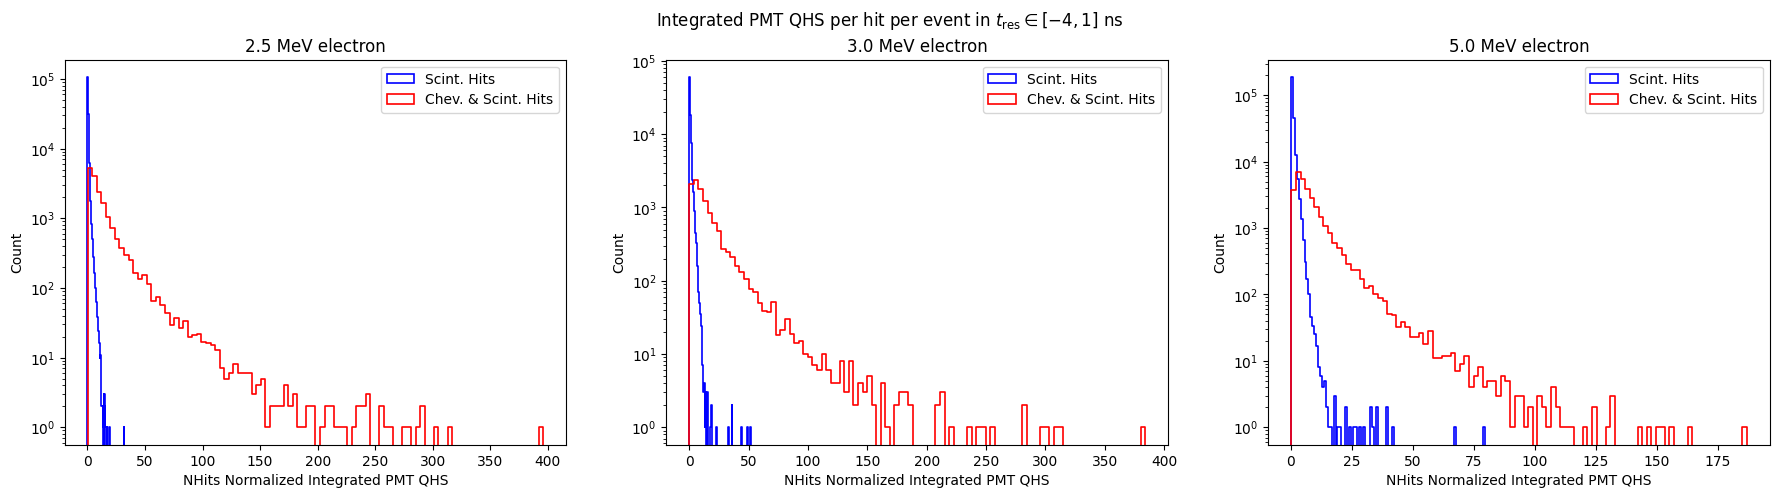

In [19]:
bins = 100

unique_en = np.unique(energy_mc_cut)

fig, axes = plt.subplots(1, len(unique_en), figsize = (22, 5))

for i_dx, energy_i in enumerate(unique_en):

    energy_mask_scint = (reduced_energy_scint == energy_i)
    energy_mask_cher_scint = (reduced_energy_cher_scint == energy_i)
    
    axis = axes[i_dx]
    
    sn.histplot(norm_q_per_pmt_scint[energy_mask_scint], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue', ax = axis)
    sn.histplot(norm_q_per_pmt_cher_scint[energy_mask_cher_scint], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red', ax = axis)
    
    axis.set_xlabel('NHits Normalized Integrated PMT QHS')
    
    axis.legend()
    axis.set_yscale('log')
    
    axis.set_title(f'{energy_i} MeV electron')

plt.suptitle(rf'Integrated PMT QHS per hit per event in $t_\text{{res}} \in [{tres_inf_cut}, {tres_sup_cut}]$ ns')

plt.show()